BERT is a `bidirectional transformer encoder pretrained on unlabeled text to predict masked tokens in a sentence and to predict whether one sentence follows another`. The main idea is that by `randomly masking some tokens`, the model can `train on text to the left and right`, giving it a more thorough understanding. BERT is also very versatile because its learned language representations can be adapted for other NLP tasks by fine-tuning an additional layer or head.

**1. How does BERT work and why is it important?**

Imagine a sentence: “She plays the violin beautifully.” Traditional language models would process this sentence from left to right, missing the crucial fact that the identity of the instrument (“violin”) impacts the interpretation of the entire sentence. BERT, however, understands that the `context-driven relationship between words` plays a pivotal role in deriving meaning. It captures the essence of bidirectionality, allowing it to consider the complete context surrounding each word, revolutionizing the accuracy and depth of language understanding.

At its core, BERT is powered by Transformers self-attention, allowing BERT to `weigh the significance of each word based on its context, both preceding and succeeding`. This `context-awareness` enables BERT the ability to generate contextualized word embeddings, which are representations of words considering their meanings within sentences. It’s akin to BERT reading and re-reading the sentence to gain a deep understanding of every word’s role.

Consider the sentence: “The ‘lead’ singer will ‘lead’ the band.” Traditional models might struggle with the ambiguity of the word “lead.” BERT, however, effortlessly distinguishes that the first “lead” is a noun, while the second is a verb, showcasing its prowess in disambiguating language constructs.





### **BERT’s Training Process**

- Pretraining Phase
    - Masked Language Model (MLM) Objective
    - Next Sentence Prediction (NSP) Objective

When `training language models`, there is a challenge of defining a prediction goal. Many `models predict the next word in a sequence` (e.g. “The child came home from ___”), a directional approach which inherently limits context learning. To overcome this challenge, BERT uses two training strategies:



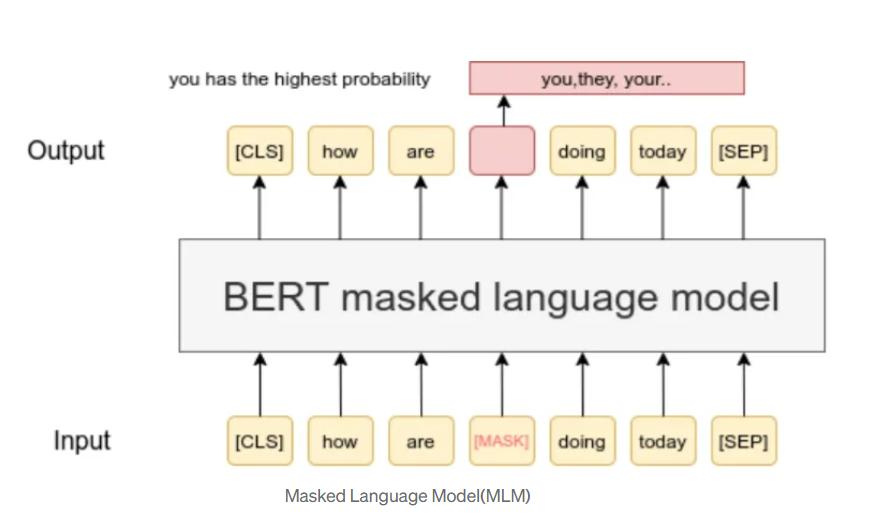

#### 1. **Masked LM (MLM)**

Before feeding word sequences into BERT, 15% of the words in each sequence are replaced with a [MASK] token. The model then attempts to predict the original value of the masked words, based on the context provided by the other, non-masked, words in the sequence. In technical terms, the prediction of the output words requires:

- Adding a classification layer on top of the encoder output.
- Multiplying the output vectors by the embedding matrix, transforming them into the vocabulary dimension.
- Calculating the probability of each word in the vocabulary with softmax.

Note: The BERT loss function takes into consideration only the prediction of the masked values and ignores the prediction of the non-masked words. As a consequence, the model converges slower than directional models, a characteristic which is offset by its increased context awareness.



#### 2. **Next Sentence Prediction (NSP)**

In the BERT training process, the model receives pairs of sentences as input and learns to predict if the second sentence in the pair is the subsequent sentence in the original document. During training, 50% of the inputs are a pair in which the second sentence is the subsequent sentence in the original document, while in the other 50% a random sentence from the corpus is chosen as the second sentence. The assumption is that the random sentence will be disconnected from the first sentence.

To help the model distinguish between the two sentences in training, the input is processed in the following way before entering the model:(see next image - sentence/segment embedding)

- A [CLS] token is inserted at the beginning of the first sentence and a [SEP] token is inserted at the end of each sentence.
- A sentence embedding indicating Sentence A or Sentence B is added to each token. Sentence embeddings are similar in concept to token embeddings with a vocabulary of 2.
- A positional embedding is added to each token to indicate its position in the sequence.

To predict if the second sentence is indeed connected to the first, the following steps are performed:

- The entire input sequence goes through the Transformer encoder model.
- The output of the [CLS] token is transformed into a 2×1 shaped vector, using a simple classification layer (learned matrices of weights and biases).
- Calculating the probability of IsNextSequence with softmax.(binary classification)

Note: When training the BERT model, Masked LM and Next Sentence Prediction are trained together, with the goal of minimizing the combined loss function of the two strategies.

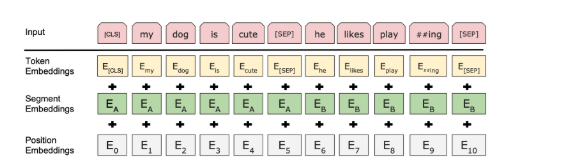

#### **Preprocessing Text for BERT**

Before BERT can work its magic on text, it needs to be prepared and structured in a way that it can understand.


- Tokenization
- Input Formatting (numericalization and tensor)
- Masked Language Model (MLM) ans NSP Objective


**Tokenization:** Breaking Text into Meaningful Chunks.

Imagine you’re teaching BERT to read a book. You wouldn’t hand in the entire book at once; you’d break it into sentences and paragraphs. Similarly, BERT needs text to be broken down into smaller units called tokens. But here’s the twist: BERT uses `WordPiece tokenization`. It splits words into smaller pieces, like turning “running” into “run” and “ning.” This helps handle tricky words and ensures that BERT doesn’t get lost in unfamiliar words.

Example:

Original Text: “ChatGPT is fascinating.” WordPiece Tokens: [“Chat”, “##G”, “##PT”, “is”, “fascinating”, “.”]

**Input Formatting:** Giving BERT the Context.

BERT loves context, and we need to serve it to it on a platter. To do that, we format the tokens in a way that BERT understands. We add `special tokens like[CLS] (stands for classification) at the beginning and [SEP] (stands for separation) between sentences`. We also assign `segment embeddings` to tell BERT `which tokens belong to which sentence`. (`Next Sentence Prediction` - hidden objective of BERT)

Eg:

Original Text: “ChatGPT is fascinating.” Formatted Tokens: [“[CLS]”, “Chat”, “##G”, “##PT”, “is”, “fascinating”, “.”, “[SEP]”]

**Masked Language Model (MLM) Objective:** Teaching BERT Context

BERT’s secret sauce lies in its ability to understand the **bidirectional context**. During its training, some words are masked (replaced with [MASK]) in sentences, and BERT learns to predict those words from their context. This helps BERT grasp how words relate to each other, both before and after.

Eg:

Original Sentence: “The cat is on the mat.” Masked Sentence: “The [MASK] is on the mat.”

Training the language model in BERT is done by predicting 15% of the tokens in the input, that were randomly picked. These tokens are pre-processed as follows — 80% are replaced with a “[MASK]” token, 10% with a random word, and 10% use the original word. The intuition that led the authors to pick this approach is as follows:

- If we used [MASK] 100% of the time the model wouldn’t necessarily produce good token representations for non-masked words. The non-masked tokens were still used for context, but the model was optimized for predicting masked words.
- If we used [MASK] 90% of the time and random words 10% of the time, this would teach the model that the observed word is never correct.
- If we used [MASK] 90% of the time and kept the same word 10% of the time, then the model could just trivially copy the non-contextual embedding.

#### **Fine-Tuning BERT for Specific Downstream Tasks**

- Transfer Learning in NLP
- Text Classification
- Sentiment Analysis
- NER
- POS Tagging
- BERT for Sequence-to-Sequence Tasks
    - Text Summarization
    - Language Translation
    - Conversational AI (Q and A)

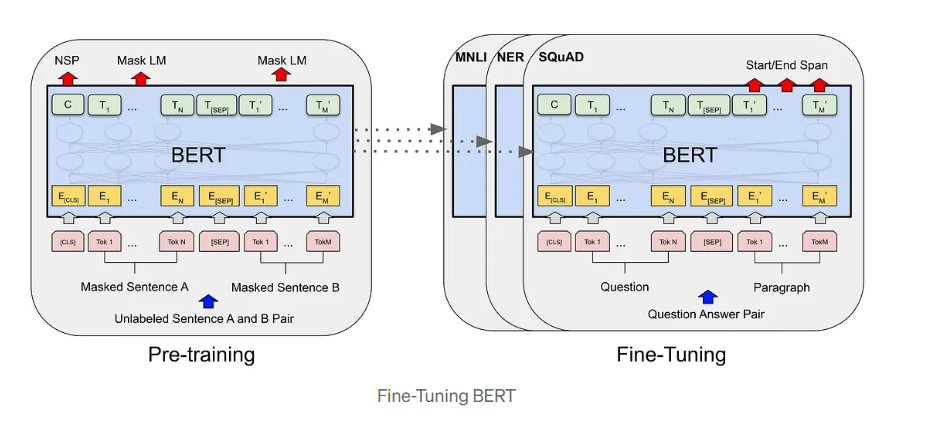

One can fine-tune BERT for specific language tasks. This involves adapting the pre-trained BERT model to perform tasks like text classification, NER and so on.
Using BERT for a specific task is relatively straightforward. BERT can be used for a wide variety of language tasks, while only adding a small layer to the core model.

- Classification tasks such as sentiment analysis are done similarly to Next Sentence classification, by adding a classification layer on top of the Transformer output for the [CLS] token.

- In Question Answering tasks (e.g. SQuAD v1.1), the software receives a question regarding a text sequence and is required to mark the answer in the sequence. Using BERT, a Q&A model can be trained by learning two extra vectors that mark the beginning and the end of the answer.

- In Named Entity Recognition (NER), the software receives a text sequence and is required to mark the various types of entities (Person, Organization, Date, etc) that appear in the text. Using BERT, a NER model can be trained by feeding the output vector of each token into a classification layer that predicts the NER label.

- In the fine-tuning training, most hyper-parameters stay the same as in BERT training, and the paper gives specific guidance (Section 3.5) on the hyper-parameters that require tuning. The BERT team has used this technique to achieve state-of-the-art results on a wide variety of challenging natural language tasks, detailed in Section 4 of the paper.

**BERT Embeddings**

- Word Embeddings vs. Contextual Word Embeddings
- WordPiece Tokenization
- Positional Encodings

**Word Embeddings vs. Contextual Word Embeddings**

BERT takes word embeddings a step further with contextual word embeddings. Instead of just having one code word for each word, BERT creates different embeddings for the same word based on its context in a sentence. This way, each word’s representation is more nuanced and informed by the surrounding words.

**WordPiece Tokenization: Handling Complex Vocabulary**

BERT’s vocabulary is like a puzzle made of smaller pieces called subwords. It uses WordPiece tokenization to break down words into these subwords. This is particularly useful for handling long and complex words, as well as for tackling words it hasn’t seen before(OOV words).

**Positional Encodings: Navigating Sentence Structure**

Since BERT reads words in a bidirectional manner, it needs to know the position of each word in a sentence. Positional encodings are added to the embeddings to give BERT this spatial awareness. This way, BERT knows not just what words mean, but also where they belong in a sentence.



**BERT’s Advanced Techniques**

- Handling Out-of-Vocabulary (OOV) Words
- Domain Adaptation with BERT
- Knowledge Distillation from BERT

**Handling Out-of-Vocabulary (OOV) Words**

BERT’s vocabulary isn’t infinite, so it can encounter words it doesn’t recognize. When handling OOV words, you can split them into subwords using WordPiece tokenization. Alternatively, you can replace them with a special token, like “[UNK]” for unknown. Balancing OOV strategies is a skill that improves with practice.

**Domain Adaptation with BERT: Making BERT Yours**

BERT, though powerful, may not perform optimally in every domain. Domain adaptation involves fine-tuning BERT on domain-specific data. By exposing BERT to domain-specific text, it learns to understand the unique language patterns of that domain. This can greatly enhance its performance for specialized tasks.

**Knowledge Distillation from BERT: Passing on the Wisdom**

Knowledge distillation involves training a smaller model (student) to mimic the behavior of a larger, pre-trained model (teacher) like BERT. This compact model learns not just the teacher’s predictions but also its confidence and reasoning. This approach is particularly useful when deploying BERT on resource-constrained devices.

**Recent Developments and Variants**

- BERT’s Architecture Variations (BERT-base, BERT-large, etc.)
- RoBERTa (A Stronger Baseline)
- ALBERT (A Lite BERT)
- DistilBERT (Compact Version)
- ELECTRA (Efficiently Learning an Encoder)

**Common Challenges and Mitigations**

- BERT’s Computational Demands
- Addressing Long Sequences

    BERT has a maximum token limit for input, and long texts can get cut off. To mitigate this, you can split the text into manageable chunks and process them separately. You’ll need to carefully manage the context between these chunks to ensure meaningful results.

- Overcoming Biases in BERT


Note that **BERT does *not* use a causal mask** as in GPT Models

---

### What Is a Causal Mask?

A **causal mask** (also called a **look-ahead mask**) ensures that, during self-attention, a token can **only attend to itself and previous tokens**, *not* future ones.

This is crucial in **autoregressive models** like:

* GPT (Generative Pretrained Transformer)
* Language models for text generation

These models are trained to **predict the next token**, so they must not "peek" at future tokens during training.

---

### What Does BERT Use Instead?

**BERT uses *bidirectional* attention.**

* That means **every token can attend to every other token** — before and after — in the same input.
* There is **no restriction** (no causal masking).
* It is trained with **Masked Language Modeling (MLM)** instead of next-token prediction.

---

### Why No Causal Mask in BERT?

Because BERT is **not a generative model** like GPT — it is a **denoising autoencoder** trained with:

1. **Masked Language Modeling (MLM)**:

   * Random tokens in the sequence are replaced with `[MASK]`
   * The model tries to predict these masked tokens using **all the context**, left and right

2. **Next Sentence Prediction (NSP)**:

   * Tries to predict whether sentence B follows sentence A

To succeed at MLM, the model needs **bidirectional context** — so **causal masking would hurt**, not help.

---

### Summary

| Model       | Causal Mask      | Why?                                     |
| ----------- | ---------------- | ---------------------------------------- |
| **BERT**    | ❌ No             | Needs bidirectional context for MLM      |
| **GPT**     | ✅ Yes            | Predicts next token; must not peek       |
| **T5**      | ✅ (decoder only) | Autoregressive decoder; uses causal mask |
| **RoBERTa** | ❌ No             | Same as BERT (no causal mask)            |

---


In [ ]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("alialmulla97/i-have-a-dream-speech-by-mlk")

# print("Path to dataset files:", path)

In [4]:
!pip install -U datasets huggingface_hub fsspec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.1/512.1 kB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 106.5 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 0.31.4
    Uninstalling huggingface-hub-0.31.4:
      Successfully uninstalled huggingface-hub-0.31.4
  Attempting uninstall: datasets
    Found existing installation: datasets 2.14.4
    Uninstalling datasets-2.14.4:
      Successfully uninstalled datasets-2.14.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency 

In [ ]:
import torch, datasets

from torch import nn
import torch.nn.functional as F
import torch.optim as optim

import numpy as np
from tqdm.auto import tqdm
import re
import os
from random import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

### Load Dataset

In [ ]:
dataset = datasets.load_dataset("bookcorpus", split="train[:2%]")

Generating train split:   0%|          | 0/74004228 [00:00<?, ? examples/s]

In [ ]:
dataset

Dataset({
    features: ['text'],
    num_rows: 1480085
})

### Preprocessing

In [ ]:
dataset["text"][0]

'usually , he would be tearing around the living room , playing with his toys .'

In [ ]:
# Test
sentences = ["The Food we eat", "is what You are."]
text = [sent.lower() for sent in sentences]
print(text)

['the food we eat', 'is what you are.']


In [ ]:
# lowercase and remove punctuations
sentences = dataset["text"]

text = [sent.lower() for sent in sentences]       # lower case
text = [re.sub("[.,!?\\-]", "", sent) for sent in text]  # clean all given symbols

In [ ]:
# Test
for sentence in text:
    print(sentence)
    tokens = sentence.split()
    print(tokens)
    break

usually  he would be tearing around the living room  playing with his toys 
['usually', 'he', 'would', 'be', 'tearing', 'around', 'the', 'living', 'room', 'playing', 'with', 'his', 'toys']


In [ ]:
# Test
sentences_sample = ["the food we eat", "is what you are."]
print(sentences_sample)
print(" ".join(sentences_sample))
print(" ".join(sentences_sample).split())

['the food we eat', 'is what you are.']
the food we eat is what you are.
['the', 'food', 'we', 'eat', 'is', 'what', 'you', 'are.']


In [ ]:
# vocab and word2idx and index2word generation

# flatten and generate unique vocab
vocab = list(set(" ".join(text).split()))

# word2idx
word2idx = {"[PAD]": 0, "[CLS]": 1, "[SEP]": 2, "[MASK]": 3}  # special tokens
for idx, token in tqdm(enumerate(vocab), desc="Creating word2idx"):
    word2idx[token] = idx + 4 # because 0-3 are already occupied cuz of specials

idx2word = {v: k for k, v in word2idx.items()}
vocab_size = len(word2idx)
vocab_size

Creating word2idx: 0it [00:00, ?it/s]

94448

In [ ]:
# Test
a = []
a.append(["a", "b"])
print(a)
a.append(["c", "d"])
print(a)

[['a', 'b']]
[['a', 'b'], ['c', 'd']]


In [ ]:
# Numericalize
token_list = []
for sentence in tqdm(text, desc="Processing sentences"):
    token_list.append([word2idx[token] for token in sentence.split()])  # Final token_list contains the list of tokenized sentences

Processing sentences:   0%|          | 0/1480085 [00:00<?, ?it/s]

In [ ]:
len(token_list)

1480085

In [ ]:
text[0], token_list[0]

('usually  he would be tearing around the living room  playing with his toys ',
 [47603,
  8345,
  8119,
  59626,
  46865,
  86916,
  10267,
  5458,
  51469,
  70443,
  74741,
  75135,
  33598])

In [ ]:
text[:2], token_list[:2]

(['usually  he would be tearing around the living room  playing with his toys ',
  'but just one look at a minion sent him practically catatonic '],
 [[47603,
   8345,
   8119,
   59626,
   46865,
   86916,
   10267,
   5458,
   51469,
   70443,
   74741,
   75135,
   33598],
  [1298,
   89950,
   37123,
   78110,
   23973,
   11397,
   18053,
   60236,
   24047,
   86952,
   11417]])

### Prepare dataloader

We need to make two types of embeddings: token embedding and segment embedding

1. **Token embedding** - Given “The cat is walking. The dog is barking”, we add [CLS] and [SEP] >> “[CLS] the cat is walking [SEP] the dog is barking”.

2. **Segment embedding** - A segment embedding separates two sentences, i.e., [0 0 0 0 1 1 1 1 ]

3. **Masking** - As mentioned in the original paper, BERT randomly assigns masks to 15% of the sequence. In this 15%, 80% is replaced with masks, while 10% is replaced with random tokens, and the rest 10% is left as is. Here we specified max_mask

4. **Padding** - Once we mask, we will add padding. For simplicity, here we padded until some specified max_seq_len.

Note: positive and negative are just simply counts to keep track of the batch size. positive refers to two sentences that are really next to one another and negative refers to sentences not next to one another. we try to make sure we have 50% positive and 50% negative in a batch.

In [ ]:
def prepare_batch(batch_size=6, max_mask=5, max_seq_len=1000):
    # Here data is list[sent1tokens, sent2tokens, ...]

    batch = []

    positive = negative = 0  # count of batch size;  we want to have half batch that are positive pairs (i.e., next sentence pairs)

    while positive != (batch_size / 2) or negative != (batch_size / 2):
        # randomly choose two sentence so we can put [SEP]
        sent_a_idx, sent_b_idx = (randrange(len(sentences)), randrange(len(sentences)))

        # retrieve the 2 sentences tokens
        tokens_a, tokens_b = token_list[sent_a_idx], token_list[sent_b_idx]

        # 1. Token Embedding - Append [CLS] and [SEP]
        input_ids = [word2idx["[CLS]"]] + tokens_a + [word2idx["[SEP]"]] + tokens_b + [word2idx["[SEP]"]] # single sentences is generated from selected 2 sentences

        # 2. Segment Embedding - [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1]
        segment_ids = [0] * (1 + len(tokens_a) + 1) + [1] * (len(tokens_b) + 1)

        # 3. Masking - Masked Language Modeling
        # Mask 15%, but should be at least 1 but does not exceed max_mask
        n_pred = min(max_mask, max(1, int(round(len(input_ids) * 0.15))))
        # Get the positions that excludes CLS and SEP
        candidate_masked_positions = [idx for idx, token in enumerate(input_ids) if token != word2idx["[CLS]"] and token != word2idx["[SEP]"]]
        # Shuffle the candidate positions
        shuffle(candidate_masked_positions)

        masked_positions, masked_tokens = [], []
        # Simply loop and change the selected input_ids positions to [MASK]
        for pos in candidate_masked_positions[:n_pred]:  # just until n_pred
            masked_positions.append(pos)          # remember the position
            masked_tokens.append(input_ids[pos])  #remember the tokens
            # 80% replace with a [MASK], but 10% will replace with a random token from the vocabulary
            if random() < 0.1:  # 10%
                rand_idx = randint(0, vocab_size - 1)   # random index in vocabulary
                input_ids[pos] = word2idx[idx2word[rand_idx]]  # replace
            elif random() < 0.8: # 80%
                input_ids[pos] = word2idx["[MASK]"]
            else:   # remain as is => same token is left as is for 10%
                pass

        # 4. Padding - pad the input_ids and segment_ids until the max_seq_len
        n_pad = max_seq_len - len(input_ids)
        input_ids.extend([0] * n_pad)
        segment_ids.extend([0] * n_pad)  # 0 for segment_ids too

        # Pad the masked_tokens and masked_positions to make sure the length is max_mask. This make sure, we always have max_mask masked tokens
        if max_mask > n_pred:
            n_pad = max_mask - n_pred
            masked_tokens.extend([0] * n_pad)
            masked_positions.extend([0] * n_pad)

        # NSP: Check if first sentence is really comes before the second sentence and also make sure positive is exactly half the batch size
        if sent_a_idx + 1 == sent_b_idx and positive < batch_size / 2:  # checks if selected sentences are next to each other based on their index id
            batch.append([input_ids, segment_ids, masked_tokens, masked_positions, True])  # isNext is True => positive pair
            positive += 1
        elif sent_a_idx + 1 != sent_b_idx and negative < batch_size / 2:
            batch.append([input_ids, segment_ids, masked_tokens, masked_positions, False])  # isNext is True => negative pair
            negative += 1
    return batch

### Segment Embeddings Clarity


### **What Are Segment Embeddings in BERT?**

BERT was trained on sentence pairs (for tasks like **Next Sentence Prediction**) as well as single sequences (like for classification tasks). To help the model **differentiate** between:

* Sentence A
* Sentence B

…**segment embeddings** are introduced.

---

### **How They Work**

For each token in the input sequence:

* **Segment A tokens** → segment ID `0`
* **Segment B tokens** → segment ID `1`

So, if your input is:

```text
[CLS] The cat sat. [SEP] It was sleepy. [SEP]
```

And you tokenize it, the **segment IDs** will be:

```
[0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
```

> This tells BERT which part of the sequence belongs to which segment.

---

### **Why Are They Useful?**

Even though the model doesn’t *know* if sentence B really follows A at this point (that’s what it’s supposed to predict), it **must know which tokens belong to which sentence**. That’s what segment embeddings do — they **explicitly separate** the two parts of the input.

This helps BERT in:

* **Next Sentence Prediction (NSP)** — to reason about the relationship between segments
* **Attention mechanism** — so attention scores are influenced by the segment context

---

The model **learns** segment embeddings during training, just like word embeddings. It learns to interpret them as "this token is in sentence A or B" and uses this to help with downstream tasks like question answering, sentence similarity, etc.

---

* Segment embeddings = simple vector (`0` or `1`) indicating **sentence A or B**
* Purpose = help BERT **distinguish** sentence boundaries in a single input
* The model doesn't "know" whether B follows A (that's the main **task**) — but it **knows which sentence is which** via these embeddings.



In [ ]:
# Get the batches
batch_size = 6  # how many number of sentence pairs
max_mask   = 5  # max masked tokens
max_seq_len    = 1000 # maximum of length to be padded
batches = prepare_batch(batch_size, max_mask, max_seq_len)

In [ ]:
len(batches)

6

In [ ]:
# We can deconstruct using map and zip
input_ids, segment_ids, masked_tokens, masked_positions, isNext = map(torch.LongTensor, zip(*batches))
input_ids.shape, segment_ids.shape, masked_tokens.shape, masked_positions.shape, isNext.shape

(torch.Size([6, 1000]),
 torch.Size([6, 1000]),
 torch.Size([6, 5]),
 torch.Size([6, 5]),
 torch.Size([6]))

### What each tensor represents
We have just 6 sentence pairs for simiplicity. Here bs represents sentence pairs that we have created.

| Tensor          | Shape       | Meaning                                                                                                                                 |
| --------------- | ----------- | --------------------------------------------------------------------------------------------------------------------------------------- |
| `input_ids`     | `[6, 1000]` | 6 token sequences, each padded/truncated to length 1000. Contains token IDs for `[CLS]`, sentence A, `[SEP]`, sentence B, `[SEP]`, etc. |
| `segment_ids`   | `[6, 1000]` | Indicates which tokens belong to sentence A (`0`) and sentence B (`1`). Same length as `input_ids`.                                     |
| `masked_tokens` | `[6, 5]`    | The original token IDs that were masked for MLM, padded to `max_mask = 5` if fewer were masked.                                         |
| `masked_pos`    | `[6, 5]`    | The corresponding positions (indices) of the masked tokens in `input_ids`.                                                              |
| `isNext`        | `[6]`       | Labels for **Next Sentence Prediction** task: `1` if sentence B follows sentence A, `0` otherwise. One label per pair.                  |


In [ ]:
input_ids[0] # first pair tokenids  # pad is 0, cls is 1, sep is 2, mask is 3

tensor([    1,  8345, 94039, 47603, 57117, 45042, 33052, 75883, 94039, 29331,
        19420, 88892, 73794, 11397,     3, 71246, 40806, 61955, 46476, 74741,
        86881,  5395,  8119, 53361, 39384, 75911, 26692,     3, 20917, 45042,
         5395, 70780,     2, 73657, 11063, 86074, 31382, 77819,     3, 61515,
            2,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0, 

In [ ]:
segment_ids[0]  # first pair segmentids

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [ ]:
show_inp = [idx2word[token.item()] for token in input_ids[0]]
print(" ".join(show_inp))

[CLS] he was usually home on sundays which was why golden made oppositeit a [MASK] to keep herself busy with activities that would brewer her out of [MASK] house on that day [SEP] and keira had never been [MASK] happy [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [P

In [ ]:
masked_tokens

tensor([[65965, 61424, 10267, 58846,   679],
        [13503, 30598, 18083, 14346,     0],
        [16340, 27782, 75911, 26692,  1184],
        [18483,  5395, 73657,     0,     0],
        [75135, 36899, 10267,  4531, 39384],
        [38947, 45652, 55395, 70780,     0]])

In [ ]:
masked_positions

tensor([[38, 23, 27, 14, 12],
        [ 2, 15,  1, 24,  0],
        [33,  6, 39, 40,  7],
        [ 7,  8,  4,  0,  0],
        [31, 18, 10,  7,  6],
        [ 5, 12,  7,  4,  0]])

In [ ]:
isNext  # 0 represents if that pair is next to each other in input or not. 1 represents that the pair is next to each other in input

tensor([0, 0, 0, 1, 1, 1])

### Desgin the Bert Model

BERT only uses the Transformer encoder.

It has the following components:
- Embedding layers
- Attention Mask
- Encoder layer
- Multi-head attention
- Scaled dot product attention
- Position-wise feed-forward network
- BERT (assembling all the components)


#### Embedding
Here we simply generate the positional embedding, and sum the token embedding, positional embedding, and segment embedding together.

In [ ]:
class Embedding(nn.Module):
    def __init__(self, voc_size, max_seq_len, n_segments, d_model, device):
        super().__init__()
        self.token_embedding = nn.Embedding(voc_size, d_model)
        self.segment_embedding = nn.Embedding(n_segments, d_model)  # we have segment with 0 or 1, just 2 segments here
        self.pos_embedding = nn.Embedding(max_seq_len, d_model)  # atmost only max_seq_len tokens are allowed
        self.ln = nn.LayerNorm(d_model)
        self.max_seq_len = max_seq_len
        self.device = device

    def forward(self, input_ids, segment_ids):
        # input_ids: (bs, max_seq_len)
        seq_len = input_ids.shape[1]
        positions = torch.arange(self.max_seq_len, dtype=torch.long).to(self.device)  # (max_seq_len,)
        positions = positions.unsqueeze(0).expand_as(input_ids)     # (bs, max_seq_len)
        pos_embeds = self.pos_embedding(positions)                  # (bs, max_seq_len, d_model)
        segment_embeds = self.segment_embedding(segment_ids)        # (bs, max_seq_len, d_model)
        token_embeds = self.token_embedding(input_ids)                 # (bs, max_seq_len, d_model)
        embeds = self.ln(token_embeds + pos_embeds + segment_embeds)
        return embeds

#### Attention mask(pad mask not causal mask)

In [ ]:
def get_attention_pad_mask(seq_q, seq_k, pad_token_idx, device):
    bs, seq_len_q = seq_q.size()
    bs, seq_len_k = seq_k.size()
    pad_attn_mask = seq_k.data.eq(pad_token_idx).unsqueeze(1).to(device)  # (bs, 1, seq_len_k) # 1 for true condition and 0 for false
    pad_attn_mask = pad_attn_mask.expand(bs, seq_len_q, seq_len_k)     # (bs, seq_len_q, seq_len_k)
    return pad_attn_mask

In [ ]:
# Test
print(get_attention_pad_mask(input_ids, input_ids, word2idx["[PAD]"], device).shape)

torch.Size([6, 1000, 1000])


#### Encoder

The encoder has two main components:

- Multi-head Attention
- Position-wise feed-forward network

First let's make the wrapper called EncoderLayer

In [ ]:
class EncoderLayer(nn.Module):
    def __init__(self, n_heads, d_model, d_head, d_pffd, device) -> None:
        super().__init__()
        self.mhsa = MultiHeadSelfAttention(d_model, n_heads, d_head, device)
        self.pffd = PositionWiseFeedForward(d_model, d_pffd)

    def forward(self, inputs, attn_padded_mask):
        # inputs: (bs, seq_len, d_model), attn_padded_mask: (bs, q_seq_len, k_seq_len)
        outputs, attn = self.mhsa(inputs, inputs, inputs, attn_padded_mask)   # (bs, q_seq_len, d_model), (bs, n_heads, q_seq_len, k_seq_len)
        outputs = self.pffd(outputs)            # (bs, q_seq_len, d_model)
        return outputs, attn

In [ ]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_head, device) -> None:
        super().__init__()
        self.scale = torch.sqrt(torch.FloatTensor([d_head])).to(device)

    def forward(self, q, k, v, mask):
        # q : (bs, n_heads, q_seq_len, d_q)  # q_seq_len=k_seq_len=v_seq_len, d_q/k/v = d_head
        # k : (bs, n_heads, k_seq_len, d_k)
        # v : (bs, n_heads, v_seq_len, d_v)
        # mask: (bs, 1, q_seq_len, k_seq_len)
        scores = torch.matmul(q, k.transpose(-1, -2)) / self.scale  # (bs, n_heads, q_seq_len, k_seq_len)
        scores.masked_fill(mask, -1e10)  # Fills elements of tensor with value where mask is one
        attn = nn.Softmax(dim=-1)(scores)  # (bs, n_heads, q_seq_len, k_seq_len)
        context = torch.matmul(attn, v)    # (bs, n_heads, q_seq_len, d_v) => encoder_output
        return context, attn

In [ ]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, d_head, device) -> None:
        super().__init__()
        self.n_heads = n_heads
        self.d_model = d_model
        self.d_head = d_head
        self.d_v = d_head
        self.fc_q = nn.Linear(d_model, d_head * n_heads)
        self.fc_k = nn.Linear(d_model, d_head * n_heads)
        self.fc_v = nn.Linear(d_model, self.d_v * n_heads)
        self.device = device

    def forward(self, q, k, v, attn_pad_mask):
        # q: (bs, q_seq_len, d_model), k:(bs, k_seq_len, d_model), v: (bs, v_seq_len, d_model), attn_pad_mask: (bs, q_seq_len, k_seq_len)
        bs = q.shape[0]
        residual = q

        q = self.fc_q(q)  # (bs, q_seq_len, d_head * n_heads)
        k = self.fc_k(k)  # (bs, k_seq_len, d_head * n_heads)
        v = self.fc_v(v)  # (bs, v_seq_len, d_head * n_heads)

        q = q.view(bs, -1, self.n_heads, self.d_head).transpose(1, 2)   # (bs, q_seq_len, n_heads * d_head) => (bs, q_seq_len, n_heads,  d_head) => (bs, n_heads, q_seq_len, d_head)
        k = k.view(bs, -1, self.n_heads, self.d_head).transpose(1, 2)   # (bs, k_seq_len, n_heads * d_head) => (bs, k_seq_len, n_heads,  d_head) => (bs, n_heads, k_seq_len, d_head)
        v = v.view(bs, -1, self.n_heads, self.d_v).transpose(1, 2)      # (bs, v_seq_len, n_heads * d_head) => (bs, v_seq_len, n_heads,  d_head) => (bs, n_heads, v_seq_len, d_head)

        attn_pad_mask = attn_pad_mask.unsqueeze(dim=1).repeat(1, self.n_heads, 1, 1)  # (bs, q_seq_len, k_seq_len) => (bs, 1, q_seq_len, k_seq_len) => (bs, n_heads, q_seq_len, k_seq_len)
        context, attn =  ScaledDotProductAttention(self.d_head, self.device)(q, k, v, attn_pad_mask)  # (bs, n_heads, q_seq_len, d_v) (bs, n_heads, q_seq_len, k_seq_len)
        context = context.transpose(1, 2).contiguous().view(bs, -1, self.n_heads * self.d_v)     # (bs, q_seq_len, n_heads * d_v)
        output = nn.Linear(self.n_heads * self.d_v, self.d_model, device=self.device)(context)
        return nn.LayerNorm(self.d_model, device=self.device)(output + residual), attn   # (bs, q_seq_len, d_model), (bs, n_heads, q_seq_len, k_seq_len)


In [ ]:
class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_pffd) -> None:
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_pffd)
        self.fc2 = nn.Linear(d_pffd, d_model)

    def forward(self, x):
        # (bs, seq_len, d_model) => (bs, seq_len, d_pffd) => (bs, seq_len, d_model)
        return self.fc2(F.gelu(self.fc1(x)))  # gelu
        pass

In [ ]:
class BERTModel(nn.Module):
    def __init__(self, n_layers, n_heads, d_model, d_pffd, d_head, n_segments, vocab_size, max_seq_len, device) -> None:
        super().__init__()
        self.embedding = Embedding(vocab_size, max_seq_len, n_segments, d_model, device)
        self.layers = nn.ModuleList([EncoderLayer(n_heads, d_model, d_head, d_pffd, device) for _ in range(n_layers)])
        self.device = device
        # NSP isNext is 0 or 1
        self.classifier = nn.Linear(d_model, 2)
        self.activation = nn.Tanh()
        self.fc = nn.Linear(d_model, d_model)
        # MLM decoder is shared with embedding layer => residual
        embed_weight = self.embedding.token_embedding.weight  # (vocab_size, d_model)
        n_vocab, n_dim = embed_weight.size()
        self.decoder = nn.Linear(n_dim, n_vocab, bias=False) # MLM
        self.decoder.weight = embed_weight
        self.decoder_bias = nn.Parameter(torch.zeros(n_vocab))
        self.linear = nn.Linear(d_model, d_model)
        self.norm = nn.LayerNorm(d_model)


    def forward(self, input_ids, segment_ids, masked_positions):
        # input_ids: (bs, seq_len), segment_ids: (bs, seq_len), masked_positions: (bs, max_mask)
        embeds = self.embedding(input_ids, segment_ids)
        attn_pad_mask = get_attention_pad_mask(input_ids, input_ids, word2idx["[PAD]"], self.device)
        for layer in self.layers:
            output, attn = layer(embeds, attn_pad_mask)    # output : (bs, seq_len, d_model), attn : (bs, n_heads, d_model, d_model)

        # 1. NSP: Predict Next Sentence or Not
        h_pooled = self.activation(self.fc(output[:, 0])) # (bs, d_model)  # first token (CLS) output
        logits_nsp = self.classifier(h_pooled)          # (bs, 2)

        # 2. MLP: Predict the Masked token
        masked_pos = masked_positions[:, :, None].expand(-1, -1, output.size(-1))  # (bs, max_mask, d_model)
        h_masked = torch.gather(output, 1, masked_pos)  # masking position (bs, max_mask, d_model)
        h_masked = self.norm(F.gelu(self.linear(h_masked)))  # (bs, max_mask, n_vocab)
        logits_mlm = self.decoder(h_masked) + self.decoder_bias   # (bs, max_mask, n_vocab)
        return logits_mlm, logits_nsp   # (bs, max_mask, n_vocab), (bs, 2)

    def get_last_hidden_state(self, input_ids, segment_ids):
        embeds = self.embedding(input_ids, segment_ids)
        attn_pad_mask = get_attention_pad_mask(input_ids, input_ids, word2idx["[PAD]"], self.device)
        for layer in self.layers:
            output, attn = layer(embeds, attn_pad_mask)
        return output

This line in the BERT model:

```python
self.decoder_fc.weight = embed_weight
```

is **sharing the embedding weights** between the **input embedding layer** and the **output decoder layer** for **Masked Language Modeling (MLM)**.

---

### Why share embedding and decoder weights?

This is a **common and intentional design** choice in models like **BERT, GPT, Transformer** (original paper), because:

---

### 1. **Weight tying = Less parameters**

Instead of learning two separate matrices for:

* **Input embeddings:** shape `(vocab_size, d_model)`
* **Decoder projection:** shape `(d_model, vocab_size)`

You reuse the **same matrix** for both:

```python
self.decoder_fc.weight = self.embedding.token_embedding.weight
```

This reduces memory and computation — especially important when vocab is huge (e.g. 30k+).

---

### 2. **Semantic consistency**

The model learns that the same vector space used to understand (embed) words is also used to generate (predict) them. So:

* The input word `"apple"` has embedding `E_apple`
* Later, if the model predicts a masked token as `"apple"`, it uses the **same `E_apple.T`** during softmax scoring

This improves generalization.

---

### 3. **Empirical performance boost**

Studies (including the original Transformer and GPT papers) show this weight tying improves **language model perplexity** and **convergence**.

---

### Bias initialization

You also have:

```python
self.decoder_bias = nn.Parameter(torch.zeros(n_vocab))
```

This is separate from the tied weights. It allows the model to still learn **token-level frequency biases** — e.g., some tokens are more likely regardless of context.

Later, in the forward pass, you'll probably do:

```python
logits = self.decoder_fc(hidden_states) + self.decoder_bias
```

---

### Summary

| Component                          | Purpose                                                  |
| ---------------------------------- | -------------------------------------------------------- |
| `decoder_fc.weight = embed_weight` | Ties decoder to input embedding for MLM                  |
| `decoder_bias`                     | Adds learnable bias to each vocab token's logit          |
| 📉 Benefit                         | Fewer parameters, faster training, better generalization |

Let me know if you want to see how this gets used during the MLM prediction step!


#### Training

In [ ]:
n_layers = 12         # Number of Encoder Layers
n_heads  = 12         # Number of heads in Multi-Head Attention
d_model  = 768        # Embedding Size
d_pffd = d_model * 4  # 4 * d_model, FeedForward dimension
d_head = 64           # Dimension of K(=Q), V
n_segments = 2

num_epochs = 1000
bs = 6
max_mask = 5
max_seq_len = 1000

model = BERTModel(n_layers, n_heads, d_model, d_pffd, d_head, n_segments, vocab_size, max_seq_len, device).to(device)  # Move model to GPU
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# batches = prepare_batch(bs, max_mask, max_seq_len)
# input_ids, segment_ids, masked_tokens, masked_positions, isNext = map(torch.LongTensor, zip(*batches))

# Move inputs to GPU
input_ids = input_ids.to(device)
segment_ids = segment_ids.to(device)
masked_tokens = masked_tokens.to(device)
masked_positions = masked_positions.to(device)
isNext = isNext.to(device)

# Wrap the epoch loop with tqdm
for epoch in tqdm(range(num_epochs), desc="Training Epochs"):
    optimizer.zero_grad()
    logits_lm, logits_nsp = model(input_ids, segment_ids, masked_positions)    # logits_lm: (bs, max_mask, vocab_size) ==> (6, 5, vocab_size), logits_nsp: (bs, yes/no) ==> (6, 2)

    # 1. MLM Loss
    loss_lm = criterion(logits_lm.transpose(1, 2), masked_tokens) # logits_lm: (bs, vocab_size, max_mask) vs. masked_tokens: (bs, max_mask) # nn.CrossEntropyLoss must have the class dimension in position 1, returns scalar as reduction is mean by default

    # 2. NSP Loss
    loss_nsp = criterion(logits_nsp, isNext) # for sentence classification # logits_nsp: (bs, 2) vs. isNext: (bs, ) # note loss is scalar as reduction is mean by default

    # 3. Combined Loss
    loss = loss_lm + loss_nsp

    if epoch % 100 == 0:
        print('Epoch:', '%02d' % (epoch), 'loss =', '{:.6f}'.format(loss))

    loss.backward()
    optimizer.step()

Training Epochs:   0%|          | 0/1000 [00:00<?, ?it/s]

In [ ]:
# Save the model after training
torch.save(model.state_dict(), "bert_model.pt")
print("Model saved to bert_model.pt")

Model saved to bert_model.pt


#### Inference

In [ ]:
input_ids, segment_ids, masked_tokens, masked_pos, isNext = map(torch.LongTensor, zip(batches[2]))

input_ids = input_ids.to(device)
segment_ids = segment_ids.to(device)
masked_tokens = masked_tokens.to(device)
masked_positions = masked_pos.to(device)
isNext = isNext.to(device)

print(input_ids.shape, segment_ids.shape, masked_tokens.shape, masked_positions.shape, isNext.shape) # torch.Size([1, 1000]) torch.Size([1, 1000]) torch.Size([1, 5]) torch.Size([1, 5]) torch.Size([1])

logits_lm, logits_nsp = model(input_ids, segment_ids, masked_positions)
# logits_lm:  (1, max_mask, vocab_size) ==> (1, 5, vocab_size)
# logits_nsp: (1, yes/no) ==> (1, 2)

# Predict masked tokens: Max the probability along the vocab dim (2), [1] is the indices of the max, and [0] is the first value
logits_lm_pred = logits_lm.detach().cpu().max(dim=2)[1][0].numpy()

# Note that zero is padding we add to the masked_tokens
print("True Masked tokens (words): ",[idx2word[pos.item()] for pos in masked_tokens[0]])
print("True Masked tokens list: ",[pos.item() for pos in masked_tokens[0]])

print("Predicted Masked tokens (words): ",[idx2word[pos.item()] for pos in logits_lm_pred])
print("Predicted masked tokens list: ", [pos for pos in logits_lm_pred])

# Predict NSP
logits_nsp_pred = logits_nsp.detach().cpu().max(dim=1)[1][0].numpy()
print("isNext : ", True if isNext else False)
print("Predicted : ",True if logits_nsp_pred else False)

torch.Size([1, 1000]) torch.Size([1, 1000]) torch.Size([1, 5]) torch.Size([1, 5]) torch.Size([1])
True Masked tokens (words):  ['shaking', 'thought', 'out', 'of', 'as']
True Masked tokens list:  [16340, 27782, 75911, 26692, 1184]
Predicted Masked tokens (words):  ['posthumously', 'junctures', 'celine', 'mackenzies', 'junctures']
Predicted masked tokens list:  [np.int64(79224), np.int64(69941), np.int64(5243), np.int64(9206), np.int64(69941)]
isNext :  False
Predicted :  True


In [ ]:
masked_tokens.shape

torch.Size([1, 5])

In [ ]:
logits_lm.data.shape

torch.Size([1, 5, 94448])

In [ ]:
logits_lm.data.max(dim=2)

torch.return_types.max(
values=tensor([[122.0270, 125.5364, 120.2032, 138.7287, 128.6850]]),
indices=tensor([[79224, 69941,  5243,  9206, 69941]]))

In [ ]:
logits_lm.max(dim=2)[1] # indices

tensor([[79224, 69941,  5243,  9206, 69941]])

In [ ]:
logits_lm.max(dim=2)[1][0]

tensor([79224, 69941,  5243,  9206, 69941])

In [ ]:
logits_lm.max(dim=2)[1][0].data

tensor([79224, 69941,  5243,  9206, 69941])

In [ ]:
logits_lm.max(dim=2)[1][0].data.numpy()

array([79224, 69941,  5243,  9206, 69941])

In [ ]:
logits_nsp.data.shape

torch.Size([1, 2])

In [ ]:
logits_nsp.data.max(dim=1)

torch.return_types.max(
values=tensor([0.0138]),
indices=tensor([1]))

In [ ]:
logits_nsp.data.max(dim=1)[1]

tensor([1])

In [ ]:
logits_nsp.data.max(dim=1)[1][0]

tensor(1)

In [ ]:
logits_nsp.data.max(dim=1)[1][0].data

tensor(1)

In [ ]:
logits_nsp.data.max(dim=1)[1][0].data.numpy()

array(1)

In [22]:
# Self
import torch, datasets

from torch import nn
import torch.nn.functional as F
from torch import optim

from tqdm.auto import tqdm
from random import *
import pickle

import time, os, re

device = ("cuda" if torch.cuda.is_available() else "cpu")
SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

dataset = datasets.load_dataset("bookcorpus", split="train[:1%]")

# Lowercase
text = [sentences.lower() for sentences in dataset["text"]]

# Remove symbols
text = [re.sub("[.,!?\\-]", "", sentence) for sentence in text]

# Vocab and mappings generator
vocab = list(set(" ".join(text).split()))  # Flattening and vocab
word2idx = {"[PAD]": 0, "[CLS]": 1, "[SEP]": 2, "[MASK]": 3}  # specials
for idx, word in tqdm(enumerate(vocab), desc="Generating Vocab Mappings"):
    word2idx[word] = idx + 4
idx2word = {v: k for k, v in word2idx.items()}

# Tokenization and Numericalization
tokens_list = [[word2idx[token] for token in sentence.split()] for sentence in tqdm(text, desc="Generating Tokens List")]

# Prepare Batch Data
def prepare_batch(data, batch_size, word2idx, max_seq_len, max_mask, max_attempts=1000):
    # data: List[sentences(tokens idxs)]
    batches = []
    positive = negative = 0
    attempts = 0
    vocab_size = len(word2idx)
    while (positive != (batch_size / 2) and negative != (batch_size / 2)): # and attempts < max_attempts
        attempts += 1  # to avoid infinite loop trying when we dont have enough postives and negatives.
        # Randomly generate a sentence pair.
        sent_a_idx, sent_b_idx = randrange(len(data) - 1), randrange(len(data) - 1)
        tokens_a, tokens_b = data[sent_a_idx], data[sent_b_idx]
        input_ids = [word2idx["[CLS]"]] + tokens_a + [word2idx["[SEP]"]] + tokens_b + [word2idx["[SEP]"]]
        segment_ids = [0] * (1 + len(tokens_a) + 1) + [1] * (len(tokens_b) + 1)
        # Masking - MLM objective (15% - 80%, 10%, 10%)
        candidate_mask_positions = [idx for idx, token_idx in enumerate(input_ids) if token_idx != word2idx["[CLS]"] and token_idx != word2idx["[SEP]"]]
        shuffle(candidate_mask_positions)
        n_pred = min(max_mask, max(1, int(len(candidate_mask_positions) * 0.15)))
        masked_tokens, masked_positions = [], []
        for pos_idx in candidate_mask_positions[:n_pred]:
            masked_tokens.append(input_ids[pos_idx])
            masked_positions.append(pos_idx)
            if random() < 0.1:
                rand_idx = randint(0, vocab_size - 1)
                input_ids[pos_idx] = word2idx[idx2word[rand_idx]]
            elif random() < 0.8:
                input_ids[pos_idx] = word2idx["[MASK]"]
            else:
                pass
        # Padding
        if len(input_ids) < max_seq_len:
            n_pad = max_seq_len - len(input_ids)
            input_ids.extend([word2idx["[PAD]"]] * n_pad)
            segment_ids.extend([0] * n_pad)  # segment_ids should be only 0 0r 1
        else:
            input_ids = input_ids[:max_seq_len]
            segment_ids = segment_ids[:max_seq_len]
        # Pad the masked_tokens and masked_positions to make sure their length is max_mask.
        if max_mask > n_pred: # or len(masked_positions) < max_mask
            n_mask = max_mask - n_pred
            masked_positions.extend([word2idx["[PAD]"]] * n_mask)
            masked_tokens.extend([word2idx["[PAD]"]] * n_mask)
        else:
            masked_positions = masked_positions[:max_mask]
            masked_tokens = masked_tokens[:max_mask]

        is_next = (sent_b_idx == sent_a_idx + 1)
        if is_next and positive < (batch_size / 2):
            batches.append([input_ids, segment_ids, masked_tokens, masked_positions, True])  # isNext=True
            positive += 1
        if not is_next and negative < (batch_size / 2):
            batches.append([input_ids, segment_ids,  masked_tokens, masked_positions, False])  # isNext=False
            negative += 1
    if len(batches) < batch_size:
        print(f"Warning: Only generated {len(batches)} samples (wanted {batch_size}).")
    return batches


# Desgin Model
class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_pffd):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_pffd)
        self.fc2 = nn.Linear(d_pffd, d_model)

    def forward(self, x):
        # x: (bs, seq_len, d_model)
        x = self.fc1(x)
        return self.fc2(F.gelu(x))


class ScaledDotProductAttention(nn.Module):
    def __init__(self, d_head, device):
        super().__init__()
        self.scale = torch.sqrt(torch.FloatTensor([d_head])).to(device)

    def forward(self, q, k, v, attn_pad_mask):
        # q = k = v : (bs, n_heads, <q/k/v>_seq_len, d_<q/k/v>), attn_pad_mask: (bs, n_heads, q_seq_len, k_seq_len)
        scores = torch.matmul(q, k.transpose(-1, -2)) / self.scale # bs, n_heads, q_seq_len, k_seq_len
        if attn_pad_mask is not None:
            scores.masked_fill(attn_pad_mask, -1e10)
        attn = nn.Softmax(dim=-1)(scores)   # bs, n_heads, q_seq_len, k_seq_len
        context = torch.matmul(attn, v)  # bs, n_heads, q_seq_len, d_v
        return context, attn


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, d_head, n_heads, device):
        super().__init__()
        self.n_heads = n_heads
        self.d_q = d_head
        self.d_k = d_head
        self.d_v = d_head
        self.fc_q = nn.Linear(d_model, n_heads * self.d_q)
        self.fc_k = nn.Linear(d_model, n_heads * self.d_k)
        self.fc_v = nn.Linear(d_model, n_heads * self.d_v)
        self.attn = ScaledDotProductAttention(d_head, device)
        self.fc_out = nn.Linear(n_heads * self.d_v, d_model).to(device)
        self.norm = nn.LayerNorm(d_model, device=device)

    def forward(self, q, k, v, attn_pad_mask):
        residual = q  # bs, seq_len, d_model
        bs = q.shape[0]
        q = self.fc_q(q)   # bs, seq_len, n_heads * d_q
        k = self.fc_k(k)   # bs, seq_len, n_heads * d_k
        v = self.fc_v(v)   # bs, seq_len, n_heads * d_v

        q = q.contiguous().view(bs, -1, self.n_heads, self.d_q).transpose(1, 2)  # bs, n_heads, q_seq_len, d_q
        k = k.contiguous().view(bs, -1, self.n_heads, self.d_k).transpose(1, 2)  # bs, n_heads, k_seq_len, d_k
        v = v.contiguous().view(bs, -1, self.n_heads, self.d_v).transpose(1, 2)  # bs, n_heads, v_seq_len, d_v
        if attn_pad_mask is not None:
            attn_pad_mask = attn_pad_mask.unsqueeze(dim=1).repeat(1, self.n_heads, 1, 1)  # (bs, q_seq_len, k_seq_len) => (bs, 1, q_seq_len, k_seq_len) => (bs, n_heads, q_seq_len, k_seq_len)

        context, attn = self.attn(q, k, v, attn_pad_mask)   # (bs, n_heads, q_seq_len, d_v) (bs, n_heads, q_seq_len, k_seq_len)
        context = context.permute(0, 2, 1, 3).contiguous().view(bs, -1, self.n_heads * self.d_v)  # (bs, seq_len, n_heads * d_v)
        output = self.fc_out(context)  # (bs, q_seq_len, d_model)
        return self.norm(output + residual), attn


class Encoder(nn.Module):
    def __init__(self, d_model, d_head, d_pffd, n_heads, max_seq_len, device):
        super().__init__()
        self.mha = MultiHeadSelfAttention(d_model, d_head, n_heads, device)
        self.pffd = PositionWiseFeedForward(d_model, d_pffd)

    def forward(self, inputs, attn_pad_mask):
        output, attn = self.mha(inputs, inputs, inputs, attn_pad_mask)
        output = self.pffd(output)
        return output, attn


class Embedding(nn.Module):
    def __init__(self, vocab_size, d_model, max_seq_len, n_segments, device):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.segments_embedding = nn.Embedding(n_segments, d_model)
        self.pos_embedding = nn.Embedding(max_seq_len, d_model)
        self.norm = nn.LayerNorm(d_model)
        self.device = device

    def forward(self, input_ids, segment_ids):
        # input_ids: (bs, seq_len), segment_ids: (bs, seq_len)
        bs = input_ids.shape[0]
        seq_len = input_ids.shape[1]
        token_embeds = self.token_embedding(input_ids)
        segment_embeds = self.segments_embedding(segment_ids)
        pos = torch.arange(0, seq_len, dtype=torch.long).to(self.device)
        pos_embeds = self.pos_embedding(pos)
        embeds = self.norm(token_embeds + segment_embeds + pos_embeds)
        return embeds


class BERT(nn.Module):
    def __init__(self, vocab_size, d_model, d_head, d_pffd, max_seq_len, n_segments, n_layers, n_heads, pad_idx, device):
        super().__init__()
        self.embedding = Embedding(vocab_size, d_model, max_seq_len, n_segments, device)
        self.layers = nn.ModuleList(Encoder(d_model, d_head, d_pffd, n_heads, max_seq_len, device) for _ in range(n_layers))
        self.pad_idx = pad_idx
        self.device = device
        # NSP
        self.fc_nsp = nn.Linear(d_model, d_model)
        self.classifier = nn.Linear(d_model, 2)
        self.nsp_activation = nn.Tanh()
        # MLM
        self.fc_mlm = nn.Linear(d_model, d_model)  # MLM
        self.norm = nn.LayerNorm(d_model)
        self.decoder_fc = nn.Linear(d_model, vocab_size, bias=False)
        embed_weight = self.embedding.token_embedding.weight # Get the token embedding weight and initialize the decoder
        n_vocab, n_dim = embed_weight.size()
        self.decoder_fc.weight = embed_weight
        self.decoder_bias = nn.Parameter(torch.zeros(n_vocab))

    def make_attn_pad_mask(self, seq_q, seq_k):
        # seq_q = seq_k = (bs, seq_len)
        mask = seq_q.eq(self.pad_idx).unsqueeze(dim=1) # bs, 1, seq_len
        return mask.expand(-1, seq_k.size(1), -1).to(self.device)

    def forward(self, input_ids, segment_ids, masked_positions):
        # input_ids: (bs, seq_len), segment_ids: (bs, seq_len), masked_positions: (bs, max_mask), masked_tokens: (bs, max_mask)
        embeds = self.embedding(input_ids, segment_ids)  # (bs, seq_len, d_model)
        attn_pad_mask = self.make_attn_pad_mask(input_ids, input_ids)  # (bs, seq_len, seq_len)
        for layer in self.layers:
            output, attn = layer(embeds, attn_pad_mask)  # (bs, seq_len, d_model) (bs, n_heads, q_seq_len, k_seq_len)
        # NSP
        h_pooled = self.nsp_activation(self.fc_nsp(output[:, 0])) # (bs, seq_len, d_model) => [CLS]-> (bs, d_model)
        nsp_logits = self.classifier(h_pooled)        # (bs, 2)
        # MLM
        n_dim = output.size(-1)
        masked_positions = masked_positions[:, :, None].expand(-1, -1, n_dim) # (bs, max_mask) => (bs, max_mask, 1) => (bs, max_mask, d_model)
        h_masked = torch.gather(output, 1, masked_positions)  # Gather masking positions values from output (bs, max_mask, d_model)
        h_masked = self.norm(F.gelu(self.fc_mlm(h_masked)))  # (bs, max_mask, d_model) => (bs, max_mask, d_model)
        mlm_logits = self.decoder_fc(h_masked) + self.decoder_bias  # (bs, max_mask, n_vocab)
        return mlm_logits, nsp_logits

    def get_last_hidden_state(self, input_ids, segment_ids):
        embeds = self.embedding(input_ids, segment_ids)
        for layer in self.layers:
            _, output = layer(embeds)
        return output

# Training

# Get the Batches
bs = 6
max_mask = 5
max_seq_len = 1000
batches = prepare_batch(tokens_list, bs, word2idx, max_seq_len, max_mask)
# Tensor Conversion
input_ids, segment_ids,  masked_tokens, masked_positions, isNext = map(torch.LongTensor, zip(*batches))
print(f"input_ids: {input_ids.shape}, segment_ids: {segment_ids.shape},  masked_tokens: {masked_tokens.shape}, masked_positions: {masked_positions.shape}, isNext: {isNext.shape}")

# Move inputs to GPU
input_ids = input_ids.to(device)
segment_ids = segment_ids.to(device)
masked_tokens = masked_tokens.to(device)
masked_positions = masked_positions.to(device)
isNext = isNext.to(device)

vocab_size = len(word2idx)
d_model = 768
d_head = 64
d_pffd = d_model * 4
n_segments = 2
n_layers = 12
n_heads = 12
pad_idx = word2idx["[PAD]"]
clip = 1.0
num_epochs = 5

model = BERT(vocab_size, d_model, d_head, d_pffd, max_seq_len, n_segments, n_layers, n_heads, pad_idx, device).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

for epoch in tqdm(range(num_epochs), desc="Training Epochs"):
    optimizer.zero_grad()
    logits_lm, logits_nsp = model(input_ids, segment_ids, masked_positions)  # logits_lm: (bs, max_mask, vocab_size) ==> (6, 5, vocab_size), logits_nsp: (bs, yes/no) ==> (6, 2)
    # 1. MLM Loss
    loss_lm = criterion(logits_lm.transpose(1, 2), masked_tokens) # logits_lm: (bs, vocab_size, max_mask) vs. masked_tokens: (bs, max_mask)
    # 2. NSP Loss
    loss_nsp = criterion(logits_nsp, isNext) # for sentence classification # logits_nsp: (bs, 2) vs. isNext: (bs, )
    # 3. Combined Loss
    loss = loss_lm + loss_nsp
    if epoch % 100 == 0:
        print(f"Epoch {epoch:03d} | Loss = {loss.item():.6f}")
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
    optimizer.step()

# Save the model after training
torch.save(model.state_dict(), "bert_model.pt")  # We should save vocab, word2idx, and idx2word too
with open("vocab.pkl", "wb") as f:
    pickle.dump({"vocab": vocab, "word2idx": word2idx, "idx2word": idx2word}, f)
print("Model saved to bert_model.pt")

# Loading
model.load_state_dict(torch.load("bert_model.pt"))
with open("vocab.pkl", "rb") as f:
    data = pickle.load(f)
    vocab = data["vocab"]
    word2idx = data["word2idx"]
    idx2word = data["idx2word"]


# Inference
input_ids, segment_ids, masked_tokens, masked_pos, isNext = map(torch.LongTensor, zip(batches[2]))
input_ids = input_ids.to(device)
segment_ids = segment_ids.to(device)
masked_tokens = masked_tokens.to(device)
masked_positions = masked_pos.to(device)
isNext = isNext.to(device)
print(input_ids.shape, segment_ids.shape, masked_tokens.shape, masked_positions.shape, isNext.shape) # torch.Size([1, 1000]) torch.Size([1, 1000]) torch.Size([1, 5]) torch.Size([1, 5]) torch.Size([1])
logits_lm, logits_nsp = model(input_ids, segment_ids, masked_positions)  # (1, max_mask, vocab_size), (1, 2)

# Predict masked tokens: Max the probability along the vocab dim (2), [1] is the indices of the max, and [0] to acces the first only tensor indices
logits_lm_pred = logits_lm.detach().cpu().max(dim=2)[1][0].numpy()
print("True Masked tokens (words): ",[idx2word[pos.item()] for pos in masked_tokens[0]])
print("True Masked tokens list: ",[pos.item() for pos in masked_tokens[0]])
print("Predicted Masked tokens (words): ",[idx2word[pos.item()] for pos in logits_lm_pred])
print("Predicted masked tokens list: ", [pos for pos in logits_lm_pred])

# Predict NSP
logits_nsp_pred = logits_nsp.detach().cpu().max(dim=1)[1][0].numpy()
print("isNext : ", True if isNext else False)
print("Predicted : ",True if logits_nsp_pred else False)

Generating Vocab Mappings: 0it [00:00, ?it/s]

Generating Tokens List:   0%|          | 0/740042 [00:00<?, ?it/s]

input_ids: torch.Size([3, 1000]), segment_ids: torch.Size([3, 1000]),  masked_tokens: torch.Size([3, 5]), masked_positions: torch.Size([3, 5]), isNext: torch.Size([3])


Training Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 000 | Loss = 139.718307
Model saved to bert_model.pt
torch.Size([1, 1000]) torch.Size([1, 1000]) torch.Size([1, 5]) torch.Size([1, 5]) torch.Size([1])
True Masked tokens (words):  ['not', 'it', '[PAD]', '[PAD]', '[PAD]']
True Masked tokens list:  [31894, 41751, 0, 0, 0]
Predicted Masked tokens (words):  ['not', 'it', '[PAD]', '[PAD]', '[PAD]']
Predicted masked tokens list:  [np.int64(31894), np.int64(41751), np.int64(0), np.int64(0), np.int64(0)]
isNext :  False
Predicted :  False
